# LDI Project Inspirational Example

This project was kindly prepared by Dr. Mohammad Javad Shokri and very lightly edited by Prof Tansu Alpcan.

## Important Note
The goal of this example project is to provide you an _inspiration_ for your own project. This is **NOT** a complete project nor provides a rigid structure to follow. You should refer to LDI project manuals to _design and execute your own project using your own style_. Do **NOT** simply copy paste this as a template. _Use it as an inspiration for what can be done!_

## Project Overview

This project uses the **PAMAP2 Physical Activity Monitoring** dataset to demonstrate how deep learning can be applied to **wearable sensor data**.  
We focus on two predictive tasks:

- **Activity Recognition (Classification):** Predict which activity a subject is performing (e.g., walking, running, cycling) from short windows of wearable signals.  
- **Heart Rate Prediction (Regression):** Predict the average heart rate during a time window using only motion sensor signals.  

# Dataset and Data Analysis

## PAMAP2 Physical Activity Monitoring Dataset

- **Source:** [PAMAP2 Physical Activity Monitoring](https://archive.ics.uci.edu/dataset/231/pamap2+physical+activity+monitoring) from the UCI Machine Learning Repository  
- **Source (paper):** Reiss, Attila and Didier Stricker. “Introducing a New Benchmarked Dataset for Activity Monitoring.” 2012 16th International Symposium on Wearable Computers (2012): 108-109.
- **Subjects:** 9 total participants in PAMAP2 — *this demo uses data from only 2 subjects for simplicity and speed*.
- **Sensors:**  
  - 3 wearable IMUs (hand, chest, ankle), each recording:  
    - accelerometer (±16g and ±6g ranges)  
    - gyroscope  
    - magnetometer  
    - temperature  
    - orientation (not reliable in this dataset)  
  - 1 heart rate monitor  
- **Signals:** 51 IMU channels + heart rate + activity ID + timestamp  
- **Sampling rate:** originally recorded at **100 Hz**, but **downsampled to 25 Hz** for this project to reduce size and runtime.  
- **Activities recorded:** lying, sitting, standing, walking, running, cycling, Nordic walking, ascending/descending stairs, etc.

## Reproducibility: Setting Random Seeds

Machine learning experiments often involve randomness — for example, in weight initialization, data shuffling, or GPU operations.  
To ensure that results are **repeatable** (i.e., running the same code twice gives the same outcome), we set a **seed** for all random number generators.  

- **Seed:** a fixed starting point for random number generation. Using the same seed ensures the "random" sequences are identical across runs.  
- We apply the seed to:  
  - Python’s built-in `random` module  
  - NumPy random generator  
  - PyTorch (CPU and CUDA, including multi-GPU setups)  

This makes experiments more reliable and easier to compare, especially during debugging or when reporting results.

In [2]:
# --- Reproducibility seeds ---
import os
import random
import numpy as np
import torch
SEED = 42  # or any integer you prefer
# Python built-in RNG
random.seed(SEED)
# NumPy
np.random.seed(SEED)
# PyTorch (both CPU and CUDA)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)  # if using multi-GPU

## Step 1: Download and Extract the Dataset

For this project, **a reduced version of the PAMAP2 dataset (2 subjects, downsampled to 25 Hz)** is already provided to you.  

In the local version, you should place the two zip files "subject101.zip" and "subject103.zip" to the same folder as your Jupyter notebook.

## Step 2: Dataset Characteristics

Before diving into data preprocessing and model training, it is important to understand the **basic characteristics of the dataset**.  
In this step, we will:

- Look at the **sampling frequency** of the signals (originally 100 Hz, downsampled here to 25 Hz).  
- Check the **distribution of activities** across time and subjects.  
- Explore **signal behavior** (e.g., heart rate and IMU channels) during different activities.  

This exploratory step helps us confirm data quality, spot irregularities, and build intuition about the patterns we want our models to learn.


To begin exploring the dataset, we first load **one subject file** (`subject101.dat`) as a demo.

- Each row corresponds to a **single timestamped sample**.  
- The columns include:  
  1. **`timestamp`** — recording time (in seconds).  
  2. **`activityID`** — numeric code for the activity being performed.  
  3. **`heart_rate`** — heart rate in beats per minute (BPM).  
  4. **51 sensor channels** (`signal_1 … signal_51`) — measurements from the IMU sensors (hand, chest, ankle).  

We use **pandas** to read the file:
- The files are **space-delimited**.  
- Missing values are marked with `-1`, which we replace with `NaN` for easier handling later.  

Finally, we check:
- The **shape** of the loaded DataFrame.  
- The **first few rows** to confirm correct loading.


In [3]:
# Load one subject file as an example (Subject101 for demo)
# Each row: timestamp, heart rate, 51 sensor channels

import os
import pandas as pd

#file_path = os.path.join("PAMAP2_Dataset", "PAMAP2_Dataset", "Protocol", "subject101.dat")


# Column names: (Timestamp, ActivityID, heart_rate) + 51 sensor signals (dataset documentation)
columns = ["timestamp", "activityID", "heart_rate"] + [f"signal_{i}" for i in range(1,52)]

# Read the file (space-delimited, missing values = -1)
df = pd.read_csv("subject101.zip", sep=" ", header=None, names=columns, compression='zip')

# Replace -1 with NaN for easier handling of missing values
df.replace(to_replace=pd.NA, value=pd.NA, inplace=True)

print("Loaded shape:", df.shape)
df.head()

Loaded shape: (94105, 54)


,timestamp,activityID,heart_rate,signal_1,signal_2,signal_3,signal_4,signal_5,signal_6,signal_7,...,signal_42,signal_43,signal_44,signal_45,signal_46,signal_47,signal_48,signal_49,signal_50,signal_51
0,8.38,0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,8.76165,3.35465,...,0.008300,0.009250,-0.017580,-61.1888,-38.9599,-58.1438,1.0,0.0,0.0,0.0
1,8.42,0,NaN,30.0,2.22936,8.83122,3.70000,2.23055,8.59741,3.76295,...,0.012698,-0.014303,-0.002823,-61.5199,-39.3879,-58.2694,1.0,0.0,0.0,0.0
2,8.46,0,NaN,30.0,2.33951,9.13251,3.54668,2.44371,8.98841,3.62596,...,0.013747,-0.010042,0.017701,-61.2916,-39.6182,-58.1499,1.0,0.0,0.0,0.0
3,8.50,0,NaN,30.0,2.44995,8.71431,3.54974,2.44016,8.70136,3.49069,...,0.040113,-0.035645,-0.006889,-60.5181,-38.9803,-58.3970,1.0,0.0,0.0,0.0
4,8.54,0,NaN,30.0,2.52392,9.05417,3.43424,2.53098,8.88181,3.35429,...,0.012354,0.000464,0.008343,-61.4090,-38.9587,-57.6468,1.0,0.0,0.0,0.0


**Sampling Frequency and Duration**

Next, we analyze the timestamps of **Subject 101** to check two key aspects:

- The IMU sensors were **downsampled** to approximately **25 Hz** (time step Δt ≈ 0.04 seconds).  
- The full recording spans about **60 minutes** in total duration.


In [4]:
# Sampling-frequency for Subject 101

import numpy as np
import matplotlib.pyplot as plt

ts = df["timestamp"].dropna().to_numpy()
num_rows = len(df)

# --- 1) Estimate sampling frequency from timestamp deltas ---
dts = np.diff(ts)
dts = dts[dts > 0]  # remove zeros/negatives if any
mean_dt = float(np.mean(dts)) if dts.size else np.nan
est_hz_mean = (1.0 / mean_dt) if (dts.size and mean_dt > 0) else np.nan

# --- 2) Total duration (in minutes) and rows-per-second ---
total_duration_s = float(ts.max() - ts.min()) if ts.size else np.nan
total_minutes = total_duration_s / 60.0 if total_duration_s > 0 else np.nan
rows_per_second = (num_rows / total_duration_s) if total_duration_s > 0 else np.nan

# --- Print a compact summary ---
print("=== PAMAP2 Sampling Summary ===")
print(f"Rows                          : {num_rows:,}")
print(f"Total duration (s)            : {total_duration_s:.2f}")
print(f"Total duration (min)          : {total_minutes:.2f}")
print(f"Mean   Δt (s)                 : {mean_dt:.5f}")
print(f"Estimated Hz (1/mean Δt)      : {est_hz_mean:.2f}")
print(f"Rows per second (rows/dur)    : {rows_per_second:.2f}")


=== PAMAP2 Sampling Summary ===
Rows                          : 94,105
Total duration (s)            : 3764.16
Total duration (min)          : 62.74
Mean   Δt (s)                 : 0.04000
Estimated Hz (1/mean Δt)      : 25.00
Rows per second (rows/dur)    : 25.00


**Activity Distribution**

We map the numeric **activity IDs** to human-readable labels and plot the activity distribution for **Subject 101**.  

This shows the number of samples recorded for each activity, highlighting which activities are well-represented and which are relatively sparse. Such imbalances are important to keep in mind for model training and evaluation.

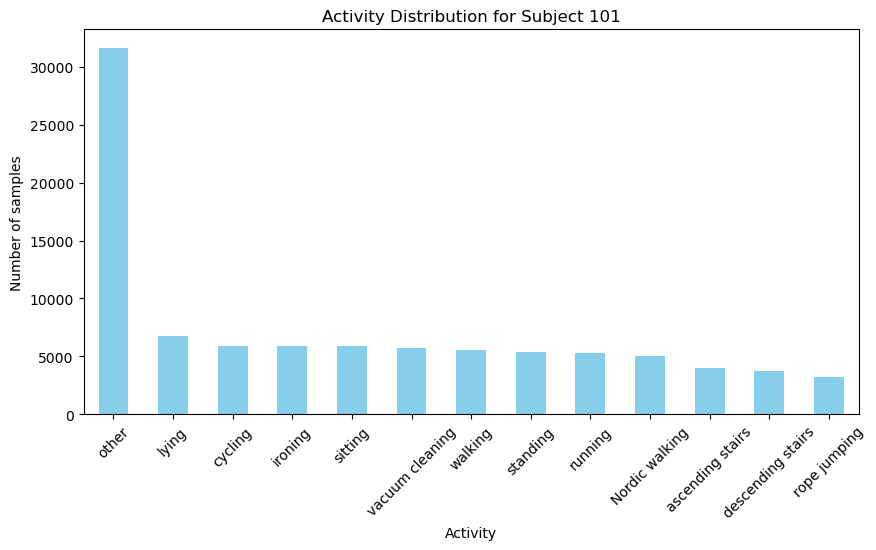

In [5]:
import matplotlib.pyplot as plt

# Activity ID → Name mapping
ACTIVITY_LABELS = {
    0:  "other",
    1:  "lying",
    2:  "sitting",
    3:  "standing",
    4:  "walking",
    5:  "running",
    6:  "cycling",
    7:  "Nordic walking",
    9:  "watching TV",
    10: "computer work",
    11: "car driving",
    12: "ascending stairs",
    13: "descending stairs",
    16: "vacuum cleaning",
    17: "ironing",
    18: "folding laundry",
    19: "house cleaning",
    20: "playing soccer",
    24: "rope jumping"
}

# Add an "activity_name" column
df["activity_name"] = df["activityID"].map(ACTIVITY_LABELS)

# Activity counts for Subject 101
activity_counts = df['activity_name'].value_counts().sort_values(ascending=False)

plt.figure(figsize=(10,5))
activity_counts.plot(kind="bar", color="skyblue")
plt.title("Activity Distribution for Subject 101")
plt.xlabel("Activity")
plt.ylabel("Number of samples")
plt.xticks(rotation=45)
plt.show()


**Activity Distribution Across Subjects**

To compare activity distribution between participants (2 subjects), we combine recordings from the 2 subjects.  
Each subject’s data is labeled with their ID, and we plot a grouped count distribution of activity samples per subject.  

This visualization highlights:  
- Which activities are consistently performed by both subjects.  
- Imbalances where certain activities are missing or underrepresented for a participant.  
- Differences in recording length and contribution of each subject.

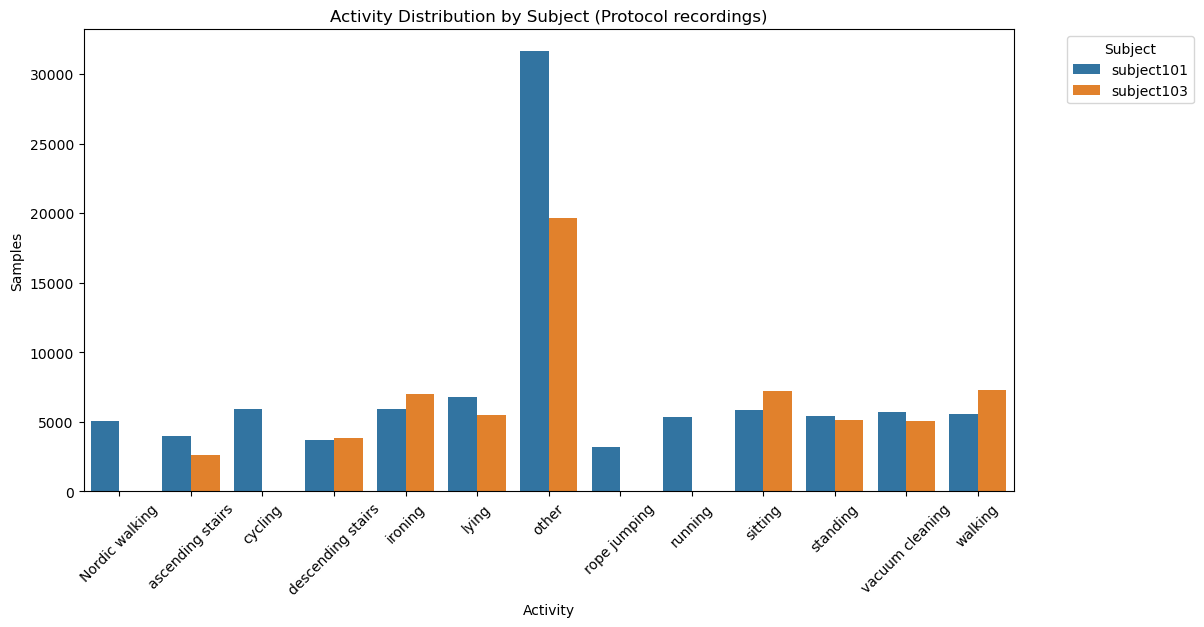

In [6]:
import seaborn as sns

# Load all subject files (Protocol folder)
import glob
files = glob.glob(os.path.join("subject*.zip"))

all_dfs = []
for file in files:
    sid = os.path.basename(file).replace(".zip", "")
    temp = pd.read_csv(file, sep=" ", header=None, names=columns, na_values=-1, compression='zip')
    temp["subject_id"] = sid
    all_dfs.append(temp)


pamap_all = pd.concat(all_dfs, ignore_index=True)
# Apply mapping to all subjects
pamap_all["activity_name"] = pamap_all["activityID"].map(ACTIVITY_LABELS)

plt.figure(figsize=(12,6))
sns.countplot(data=pamap_all, x="activity_name", hue="subject_id", palette="tab10",
              order=sorted(pamap_all["activity_name"].dropna().unique()))
plt.title("Activity Distribution by Subject (Protocol recordings)")
plt.xlabel("Activity")
plt.ylabel("Samples")
plt.xticks(rotation=45)
plt.legend(title="Subject", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()


**Heart Rate Over Time by Activity**

This plot shows the **heart rate of Subject 101 over time**, color-coded by the activity being performed.  

- Each point represents a heart rate measurement at a given timestamp.  
- Activities are distinguished using a consistent colormap and labeled in the legend.  
- The visualization reveals how heart rate fluctuates depending on the type and intensity of activity (e.g., higher during running or cycling, lower when lying or sittiivities.

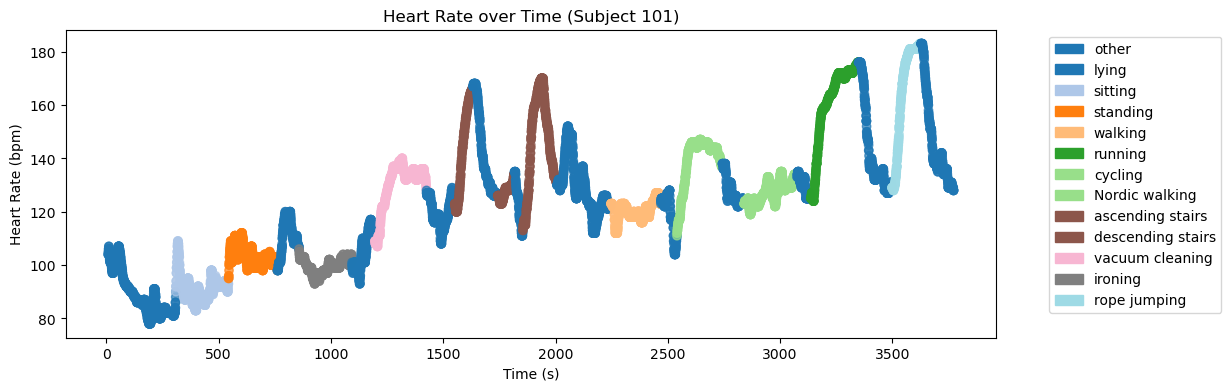

In [10]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# Set up the same colormap and normalization as scatter
cmap = plt.get_cmap('tab20')
norm = mcolors.Normalize(vmin=df['activityID'].min(), vmax=df['activityID'].max())

plt.figure(figsize=(12,4))
sc = plt.scatter(df['timestamp'], df['heart_rate'], 
                 c=df['activityID'], cmap=cmap, alpha=0.7)
plt.title("Heart Rate over Time (Subject 101)")
plt.xlabel("Time (s)")
plt.ylabel("Heart Rate (bpm)")

# Build legend with correct colors
handles = []
for i in sorted(df['activityID'].dropna().unique()):
    color = cmap(norm(i))
    label = ACTIVITY_LABELS.get(int(i), str(int(i)))
    handles.append(mpatches.Patch(color=color, label=label))

plt.legend(handles=handles, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

**Example Sensor Signals for Selected Activities**

To better understand the raw input data, we plot the **ankle accelerometer signals** for a few representative activities for **Subject 101**:

- Running  
- Cycling  
- Lying  
- Rope jumping  

Each subplot shows the acceleration patterns over 500 samples.  

This highlights how different activities produce distinct motion signatures:  
- **Running and rope jumping** show strong periodic oscillations.  
- **Cycling** has a smoother, repetitive pattern.  
- **Lying** remains mostly flat with minimal movement.  

Such differences are what allow machine learning models to distinguish between activities.


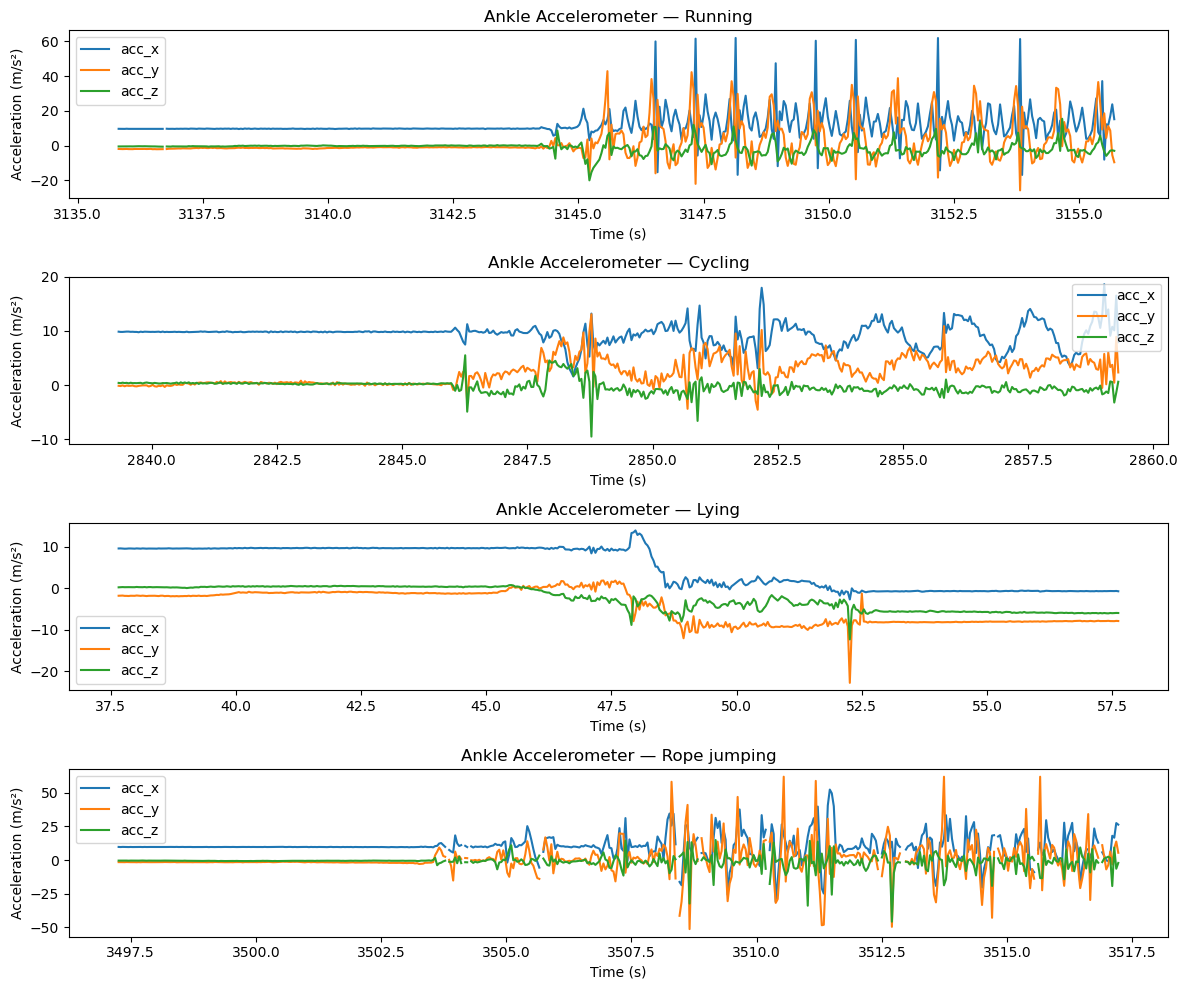

In [11]:
# Pick activities to visualize
activities_to_plot = ["running", "cycling", "lying", "rope jumping"]

plt.figure(figsize=(12, 10))

for idx, act in enumerate(activities_to_plot, 1):
    # Take first ~500 rows of that activity (contiguous window)
    subset = df[df["activity_name"] == act].iloc[:500]

    plt.subplot(4, 1, idx)
    plt.plot(subset["timestamp"], subset["signal_39"], label="acc_x")
    plt.plot(subset["timestamp"], subset["signal_40"], label="acc_y")
    plt.plot(subset["timestamp"], subset["signal_41"], label="acc_z")

    plt.title(f"Ankle Accelerometer — {act.capitalize()}")
    plt.xlabel("Time (s)")
    plt.ylabel("Acceleration (m/s²)")
    plt.legend()

plt.tight_layout()
plt.show()

## Step 3: Augmentation and Preprocessing Functions, and Dataset Class (both tasks)

To prepare the raw PAMAP2 signals for deep learning, we build a preprocessing pipeline and a custom PyTorch `Dataset`:

- **Signal selection:** Use all IMU channels (`signal_*` columns).  
- **Preprocessing:**  
  - Coerce numeric values  
  - Sort by timestamp  
  - Replace missing values (with interpolation/backfill/forward fill)  
- **Normalization:** Apply z-score scaling using mean/std computed on the training set.  
- **Windowing:** Split continuous signals into fixed-length windows (default = 4 seconds at 25 Hz → 100 samples).  
  - *Classification:* label = majority activity ID within the window.  
  - *Regression:* label = mean heart rate in the window.  
- **Augmentation:** Lightweight time-series augmentations (jitter, time shift, time masking, channel dropout) can be applied during training.  
- **PyTorch Dataset:** Returns `(window, label)` pairs ready for batching.  

This ensures consistent preprocessing and enables both classification (activity recognition) and regression (heart rate prediction) tasks from the same dataset.

**Preprocessing, Normalization and Windowing Functions**

In [12]:
# === PAMAP2 preprocessing  ===
# - Task = "classification" (X = IMU + HR, y = activityID) OR "regression" (X = IMU, y = heart_rate)
# - Windowing: 4s windows @25Hz -> default window_size=100 (configurable)
# - Normalization: z-score with stats you pass in (fit on train only)

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

# ---------- helpers ----------
def get_imu_cols(df):
    """Return all IMU signal columns (sorted by index if named signal_1..)."""
    imu_cols = [c for c in df.columns if c.startswith("signal_")]
    # sort by numeric suffix if present
    try:
        imu_cols = sorted(imu_cols, key=lambda c: int(c.split("_")[1]))
    except:
        imu_cols = sorted(imu_cols)
    return imu_cols


def preprocess_df(df: pd.DataFrame,
                  imu_cols=None,
                  fill_method="interpolate",
                  sort_by_time=True):
    """
    Light preprocessing:
      - ensure numeric types
      - sort by timestamp
      - handle NaNs in IMU + heart_rate (interpolate -> bfill -> ffill)
    """
    df = df.copy()

    # Coerce numeric columns
    for c in ["timestamp", "activityID", "heart_rate"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    if imu_cols is None:
        imu_cols = get_imu_cols(df)

    # Sort by time if requested
    if sort_by_time and "timestamp" in df.columns:
        df = df.sort_values("timestamp").reset_index(drop=True)

    # Replace explicit -1 with NaN if still present
    num_cols = imu_cols + (["heart_rate"] if "heart_rate" in df.columns else [])
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce").replace({-1: np.nan})

    # Fill missing values for continuous signals
    if fill_method == "interpolate":
        df[num_cols] = df[num_cols].interpolate(limit_direction="both")
        df[num_cols] = df[num_cols].bfill().ffill()
    elif fill_method == "median":
        med = df[num_cols].median()
        df[num_cols] = df[num_cols].fillna(med)
    else:
        df[num_cols] = df[num_cols].fillna(0.0)

    return df


def compute_feature_stats(df: pd.DataFrame, feature_cols):
    """Return dict of mean/std for z-score normalization."""
    mu = df[feature_cols].mean(skipna=True)
    sd = df[feature_cols].std(ddof=0, skipna=True)
    sd = sd.replace(0, 1.0)
    # If a whole column is NaN in train, set neutral stats
    mu = mu.fillna(0.0)
    sd = sd.fillna(1.0)
    return {"mean": mu.to_dict(), "std": sd.to_dict()}

def apply_feature_stats(df: pd.DataFrame, feature_cols, stats):
    """Apply in-place z-score normalization using provided stats."""
    mu = pd.Series(stats["mean"])
    sd = pd.Series(stats["std"]).replace(0, 1.0)
    df.loc[:, feature_cols] = (df[feature_cols] - mu) / sd
    # Replace any leftover NaN/Inf with 0
    df.loc[:, feature_cols] = df[feature_cols].replace([np.inf, -np.inf], np.nan).fillna(0.0)
    return df


def make_windows(df: pd.DataFrame,
                 feature_cols,
                 window_size=100,
                 step_size=100,
                 task="classification"):
    """
    Turn a single subject's (already preprocessed) DataFrame into fixed-length windows.
    Labels:
      - classification: majority activityID in the window (int)
      - regression: mean heart_rate in the window (float)
    """
    X, y = [], []
    N = len(df)
    last_start = N - window_size
    for start in range(0, max(0, last_start + 1), step_size):
        sl = df.iloc[start:start+window_size]
        if len(sl) < window_size:
            continue

        x = sl[feature_cols].to_numpy(dtype=np.float32)

        if task == "classification":
            # Majority activityID (drop NaN if any)
            lbl = sl["activityID"].dropna()
            if lbl.empty:
                continue
            label = int(lbl.mode().iloc[0])
        else:
            # Regression → mean heart rate
            if "heart_rate" not in sl.columns:
                continue
            label = float(sl["heart_rate"].mean())

        X.append(x)
        y.append(label)

    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y)
    return X, y


**Data Augmentation Class for IMU Time-Series**

To improve generalization and make the model more robust to noise, we apply **lightweight data augmentations** to the IMU windows.  
Since features are z-scored (mean ≈ 0, std ≈ 1), we use **small magnitudes** for perturbations.

The augmentation class `AugmentTS` applies the following random transformations:

1. **Jitter (Gaussian noise):**  
   Adds small random noise to every value in the sequence, simulating sensor noise.  

2. **Time shift (circular roll):**  
   Shifts the entire window forward/backward by a few samples. This simulates misalignment in time while preserving signal shape.  

3. **Time masking:**  
   Randomly zeros out a short contiguous span of timesteps, forcing the model to handle missing data or dropped samples.  

4. **Channel dropout:**  
   Randomly removes some sensor channels across the whole window, imitating sensor failure or missing modalities.  

Each augmentation has a probability (`p_*`) of being applied and a maximum severity (e.g., `max_shift_frac=0.05` → at most 5% of the window length).  
These augmentations are applied **only during training**, never in validation or testing.

In [13]:
class AugmentTS:
    """
    Lightweight IMU time-series augmentations applied on (T, F) windows.
    Use small magnitudes; features are z-scored, so std ~1.
    """
    def __init__(self,
                 p_jitter=0.5,   jitter_std=0.01,
                 p_time_shift=0.3, max_shift_frac=0.05,   # up to 5% of window length
                 p_time_mask=0.3, max_mask_frac=0.10,     # mask up to 10% of timesteps
                 p_channel_drop=0.15, max_drop_frac=0.05  # drop up to 5% of channels
                 ):
        self.p_jitter = p_jitter
        self.jitter_std = jitter_std
        self.p_time_shift = p_time_shift
        self.max_shift_frac = max_shift_frac
        self.p_time_mask = p_time_mask
        self.max_mask_frac = max_mask_frac
        self.p_channel_drop = p_channel_drop
        self.max_drop_frac = max_drop_frac

    def __call__(self, x: np.ndarray) -> np.ndarray:
        # x: (T, F) numpy float32
        T, F = x.shape
        out = x.copy()

        # 1) Jitter
        if np.random.rand() < self.p_jitter:
            out += np.random.normal(loc=0.0, scale=self.jitter_std, size=out.shape).astype(out.dtype)

        # 2) Time shift (circular roll by a few samples)
        if np.random.rand() < self.p_time_shift:
            max_shift = max(1, int(self.max_shift_frac * T))
            k = np.random.randint(-max_shift, max_shift + 1)
            if k != 0:
                out = np.roll(out, shift=k, axis=0)

        # 3) Time mask (zero out a short contiguous span)
        if np.random.rand() < self.p_time_mask:
            max_len = max(1, int(self.max_mask_frac * T))
            m = np.random.randint(1, max_len + 1)
            s = np.random.randint(0, T - m + 1)
            out[s:s+m, :] = 0.0

        # 4) Channel dropout (zero out a few feature channels)
        if np.random.rand() < self.p_channel_drop:
            max_drop = max(1, int(self.max_drop_frac * F))
            d = np.random.randint(1, max_drop + 1)
            ch_idx = np.random.choice(F, size=d, replace=False)
            out[:, ch_idx] = 0.0

        return out

**Custom Dataset Class: `PAMAP2WindowDataset`**

This class converts the raw PAMAP2 time-series data into a **PyTorch `Dataset`** that yields **fixed-length windows** of sensor signals (with or without heart rate) for training deep learning models.  

Preprocessing (cleaning, normalization) and optional augmentations are applied inside this class, so the model always sees ready-to-use inputs.

In this class, we:
- Slice the continuous streams into fixed-size **windows**.  
- Label each window according to the task:  
  - **Classification:** by the majority activity ID in the window.  
  - **Regression:** by the mean heart rate in the window.  

**What it returns**
- `x`: a `(T, F)` tensor of IMU features (optionally including HR).  
- `y`:  
    - an integer class ID (for classification), or  
    - a float heart rate value (for regression).  
- Designed to plug directly into a PyTorch `DataLoader` for batching, shuffling, and parallel loading.


In [14]:
# ---------- Dataset ----------
class PAMAP2WindowDataset(Dataset):
    """
    Windowed PAMAP2 dataset for either classification or regression.

    task:
      - 'classification': features = IMU + heart_rate, target = activityID (int)
      - 'regression'    : features = IMU,               target = heart_rate (float)

    stats: normalization stats (dict with 'mean' and 'std') computed on training set.
           If None, stats are computed from provided df (OK for training; pass same stats to val/test).
    class_map: optional dict mapping raw activityID -> contiguous [0..C-1].
               If None in classification, it will be created from this dataset's labels.
    """
    def __init__(self,
                 df: pd.DataFrame,
                 window_size=100,
                 step_size=100,
                 task="classification",
                 stats=None,
                 class_map=None,
                 transform=None):      
        assert task in ("classification", "regression")
        self.task = task
        self.transform = transform    
        
        # Identify IMU feature columns (ALL signals)
        imu_cols = get_imu_cols(df)
        assert len(imu_cols) > 0, "No IMU columns found (expected columns like 'signal_1')."

        # Preprocess (clean NaNs, sort by time, etc.)
        df_proc = preprocess_df(df, imu_cols=imu_cols, fill_method="interpolate", sort_by_time=True)

        # Feature columns per task
        if task == "classification":
            feature_cols = imu_cols + (["heart_rate"] if "heart_rate" in df_proc.columns else [])
        else:  # regression
            feature_cols = imu_cols

        # Normalization
        if stats is None:
            stats = compute_feature_stats(df_proc, feature_cols)
        self.stats = stats
        df_proc = apply_feature_stats(df_proc, feature_cols, stats)

        # Build windows
        X, y = make_windows(df_proc, feature_cols,
                            window_size=window_size,
                            step_size=step_size,
                            task=task)

        # Class mapping (contiguous indices) for classification
        if task == "classification":
            uniq = np.unique(y.astype(int))
            if class_map is None:
                class_map = {int(a): i for i, a in enumerate(sorted(uniq))}
            inv_map = {v: k for k, v in class_map.items()}
            y_idx = np.array([class_map[int(a)] for a in y], dtype=np.int64)
            self.y = torch.from_numpy(y_idx)
            self.class_map = class_map
            self.inv_class_map = inv_map
        else:
            self.y = torch.from_numpy(y.astype(np.float32))
            self.class_map = None
            self.inv_class_map = None

        self.X = torch.from_numpy(X)            # shape: (num_windows, window, features)
        self.feature_cols = feature_cols
        self.window_size = window_size
        self.step_size = step_size

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        x = self.X[idx]               
        y = self.y[idx]
        if self.transform is not None:
            if isinstance(x, torch.Tensor):
                x_np = x.numpy()
                x_np = self.transform(x_np)
                x = torch.from_numpy(x_np.astype(np.float32))
            else:
                x = self.transform(x).astype(np.float32)
        return x, y


## Step 4 — Stratified Data Split 
  
To ensure balanced class distributions, we perform a **stratified split** into **train/val/test** (≈70/10/20) **by activity label**.

Key points:
- **Labels for stratification** come from the classification windows built over the full dataset.
- We **reuse the same window indices** for both classification and regression.


In [16]:
# === Step 4: Stratified split (by activity) ===
import os, glob
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import StratifiedShuffleSplit

#PROTOCOL_DIR = os.path.join("PAMAP2_Dataset", "PAMAP2_Dataset", "Protocol")

# timestamp, activityID, heart_rate + 51 IMU signals (signal_1..signal_51)
columns = ["timestamp", "activityID", "heart_rate"] + [f"signal_{i}" for i in range(1, 52)]

# 1) Load & concat ALL subjects (we'll ignore subject boundaries for stratified split)
dfs = []
for path in sorted(glob.glob(os.path.join("subject*.zip"))):
    df_s = pd.read_csv(path, sep=r"\s+", header=None, names=columns, na_values=-1, engine="python", compression='zip')
    dfs.append(df_s)
all_df = pd.concat(dfs, ignore_index=True)
print("All data shape:", all_df.shape)

# 2) Build a classification dataset ONCE to get window labels for stratification
WINDOW = 100   # ~4s
STEP   = 100
BATCH  = 64

# (Use your augmentation objects if already defined; None here for label extraction)
base_cls = PAMAP2WindowDataset(all_df, task="classification", window_size=WINDOW, step_size=STEP, stats=None, transform=None)
y_win = base_cls.y.numpy()  # window-level labels (already mapped to contiguous class ids)
n_windows = len(base_cls)
n_classes = int(y_win.max() + 1)
print(f"Windows built (classification): {n_windows} | classes: {n_classes}")

# 3) Stratified split on window labels: train/val/test (e.g., 70/10/20)
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
trainval_idx, test_idx = next(sss1.split(np.zeros_like(y_win), y_win))

y_trainval = y_win[trainval_idx]
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=0.125, random_state=42)  # 0.125 of 0.8 → 0.10 overall
train_idx, val_idx = next(sss2.split(np.zeros_like(y_trainval), y_trainval))

train_idx = trainval_idx[train_idx]
val_idx   = trainval_idx[val_idx]

print(f"Split sizes — train: {len(train_idx)}, val: {len(val_idx)}, test: {len(test_idx)}")


All data shape: (157314, 54)
Windows built (classification): 1573 | classes: 13
Split sizes — train: 1100, val: 158, test: 315


# Deep Learning Models and Training

We now move from **data preparation** to **training and evaluating deep learning models**.  


## Potential Deep Learning Tasks

The PAMAP2 dataset provides both motion signals (IMUs) and physiological data (heart rate), enabling different supervised learning objectives.  
Some example tasks we can design include:

---

### 1. Binary Activity Classification
- **Input:** IMU + heart rate signals (time-series windows)  
- **Label:** Binary categories such as  
  - *Active* (e.g., walking, running, cycling)  
  - *Inactive* (e.g., sitting, lying, standing)  
- **Task type:** Binary classification  
- **Goal:** Distinguish between active and inactive states.

---

### 2. Activity Recognition (Multiclass Classification)
- **Input:** IMU + heart rate signals (time-series windows)  
- **Label:** Activity ID (e.g., walking, running, cycling, sitting, lying, etc.)  
- **Task type:** Multiclass classification  
- **Example:** Predict if a subject is *walking* vs *running* from a segment of IMU data.

---

### 3. Energy Expenditure / Heart Rate Prediction (Regression)
- **Input:** IMU signals only  
- **Label:** Heart rate (continuous)  
- **Task type:** Regression  
- **Example:** Estimate a subject’s heart rate from their motion signals, linking physical activity intensity to physiological response.

## Selected Tasks

In this project we focus on:

1. **Activity Recognition (Classification):** predicting the activity label from IMU + HR signals.  
2. **Heart Rate Prediction (Regression):** estimating continuous heart rate values from IMU signals.

We will handle the two predictive tasks separately.

## Task 1: Activity Recognition (Multiclass Classification)
- **Input:** IMU + heart rate signals (time-series windows)  
- **Label:** Activity ID (e.g., walking, running, cycling, sitting, lying, etc.)  
- **Task type:** Multiclass classification  
- **Example:** Predict if a subject is *walking* vs *running* from a segment of IMU data.

### Step 5: DataLoaders (with Train-Time Augmentation)

We instantiate the **classification** datasets and loaders using the stratified window indices from Step 4.

**What & why**
- **Augmentation on train only:** `AugmentTS` adds light jitter, time shift, time masking, and channel dropout to improve generalization. Validation/test remain untouched for fair evaluation.
- **Fit normalization on train:** We first create `train_cls` with `stats=None`, which computes z-score stats on the **training windows**; the same `stats_cls` are then **reused** for `val_cls` and `test_cls` to avoid leakage.
- **Consistent label space:** We reuse `class_map` (raw activity IDs → contiguous indices) across splits so labels align.
- **Subset by stratified indices:** `Subset(...)` applies the previously computed **train/val/test window indices** to each dataset.
- **Efficient loading:**  
  - `shuffle=True` for the training loader only.  

Finally, we print a **sanity check** on batch shapes to confirm `(batch, time, features)` and the label tensor size.

In [17]:
# Classification DataLoaders (train with augmentation, val/test without)

augment_cls = AugmentTS(
    p_jitter=0.6,  jitter_std=0.02,
    p_time_shift=0.4, max_shift_frac=0.05,
    p_time_mask=0.3,  max_mask_frac=0.08,
    p_channel_drop=0.2, max_drop_frac=0.05
)


train_cls = PAMAP2WindowDataset(all_df, task="classification", window_size=WINDOW, step_size=STEP,
                                stats=None, transform=augment_cls)
stats_cls = train_cls.stats
class_map = train_cls.class_map

val_cls   = PAMAP2WindowDataset(all_df, task="classification", window_size=WINDOW, step_size=STEP,
                                stats=stats_cls, class_map=class_map, transform=None)
test_cls  = PAMAP2WindowDataset(all_df, task="classification", window_size=WINDOW, step_size=STEP,
                                stats=stats_cls, class_map=class_map, transform=None)

ds_train_cls = Subset(train_cls, train_idx)
ds_val_cls   = Subset(val_cls,   val_idx)
ds_test_cls  = Subset(test_cls,  test_idx)

print(f"[Classification] windows — train: {len(ds_train_cls)}, val: {len(ds_val_cls)}, test: {len(ds_test_cls)}")
print(f"[Classification] num_classes: {len(class_map)}  | class_map: {class_map}")

train_loader_cls = DataLoader(ds_train_cls, batch_size=BATCH, shuffle=True,  num_workers=0, pin_memory=False)
val_loader_cls   = DataLoader(ds_val_cls,   batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=False)
test_loader_cls  = DataLoader(ds_test_cls,  batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=False)


# Sanity check: feature dims
x_cls, y_cls = next(iter(train_loader_cls))
print("Batch shapes — classification:", tuple(x_cls.shape), tuple(y_cls.shape))  # (B, T, 53), (B,)

[Classification] windows — train: 1100, val: 158, test: 315
[Classification] num_classes: 13  | class_map: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 12: 8, 13: 9, 16: 10, 17: 11, 24: 12}
Batch shapes — classification: (64, 100, 52) (64,)


### Step 6 — Model

This section defines a compact sequence model for **activity recognition** and a few training utilities.

**Device selection**
We choose `cuda` if available to accelerate training on a GPU; otherwise we fall back to CPU.

**Initialization helpers (why custom init?)**
RNNs and deep nets are sensitive to initialization. We:
- **Xavier/Glorot** init for `Linear` layers → keeps activations/gradients well-scaled.
- **Orthogonal** init for LSTM recurrent weights → stabilizes long-range dynamics.
- **Forget-gate bias = 1** in LSTMs → encourages the model to retain information longer early in training, often improving convergence.

**ConvBlock1D**
We first process the time series with **1D convolutions** over time:
- Two conv layers (kernels 9 then 5) + **BatchNorm** + **ReLU** + **Dropout**.
- Purpose: learn short-term temporal patterns and denoise before the recurrent stage.
- Input/Output shapes: receives `(B, C, T)` and returns `(B, W, T)` (channels become learned features).

**BiLSTM temporal encoder**
After CNN features, we apply a **bidirectional LSTM**:
- Captures **longer-term** temporal dependencies in both forward and backward directions.
- We take the **last timestep** representation (concatenated forward/backward states) as a fixed-length summary of the window.

**Classification head**
A small **Dropout + Linear** head maps the LSTM representation to **class logits**.

**End-to-end shapes**
- Input: `(B, T, F)` → transpose to `(B, F, T)` for convolutions.
- CNN: `(B, F, T)` → `(B, W, T)`; transpose back to `(B, T, W)` for the LSTM.
- BiLSTM: `(B, T, W)` → `(B, T, 2H)`; take last timestep → `(B, 2H)`.
- Head: `(B, 2H)` → `(B, C)` logits.

**Accuracy utility**
`accuracy_from_logits` converts logits to predicted classes via `argmax` and computes the **mean accuracy** over a batch. This is used for quick training/validation feedback.

In [18]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import math
from typing import Tuple
from torch.optim.lr_scheduler import CosineAnnealingLR
import copy


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


def init_lstm_forget_bias(bias_tensor):
    # LSTM bias is [b_ii|b_if|b_ig|b_io]; set forget gate (b_if) to 1
    hidden_size = bias_tensor.numel() // 4
    with torch.no_grad():
        bias_tensor.zero_()
        bias_tensor[hidden_size:2*hidden_size].fill_(1.0)

def init_weights(model):
    for m in model.modules():
        # Linear
        if isinstance(m, nn.Linear):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)

        # Conv1d (followed by ReLU)
        elif isinstance(m, nn.Conv1d):
            nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            if m.bias is not None:
                nn.init.zeros_(m.bias)

        # BatchNorm1d
        elif isinstance(m, nn.BatchNorm1d):
            if m.weight is not None:
                nn.init.ones_(m.weight)   # gamma ← 1
            if m.bias is not None:
                nn.init.zeros_(m.bias)    # beta  ← 0

        # LSTM (covers both directions via named_parameters)
        elif isinstance(m, nn.LSTM):
            for name, param in m.named_parameters():
                if "weight_ih" in name:
                    nn.init.xavier_uniform_(param.data)
                elif "weight_hh" in name:
                    nn.init.orthogonal_(param.data)
                elif "bias_ih" in name:
                    init_lstm_forget_bias(param.data)
                elif "bias_hh" in name:
                    init_lstm_forget_bias(param.data)


# model: Tiny CNN + BiLSTM heads ===


class ConvBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, k=9, p=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=k, padding=k//2, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv1d(out_ch, out_ch, kernel_size=5, padding=2, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.ReLU(inplace=True),
            nn.Dropout(p)
        )
    def forward(self, x):  # x: (B, C, T)
        return self.net(x)

class CNNBiLSTMClassifier(nn.Module):
    """Input (B, T, F) -> logits (B, C) | uses ALL IMU + HR (F = 53)."""
    def __init__(self, n_features: int, n_classes: int, cnn_width=64, lstm_hidden=128, p=0.1):
        super().__init__()
        self.cnn = ConvBlock1D(n_features, cnn_width, p=p)      # (B, W, T)
        self.lstm = nn.LSTM(input_size=cnn_width, hidden_size=lstm_hidden,
                            num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Dropout(p),
            nn.Linear(2*lstm_hidden, n_classes)
        )

    def forward(self, x):  # x: (B, T, F)
        x = x.transpose(1, 2)           # (B, F, T)
        x = self.cnn(x)                  # (B, W, T)
        x = x.transpose(1, 2)           # (B, T, W)
        out, _ = self.lstm(x)           # (B, T, 2H)
        out = out[:, -1, :]             # last timestep
        return self.head(out)           # (B, C)


# ----- Utilities -----
@torch.no_grad()
def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = logits.argmax(dim=1)
    return (preds == y).float().mean().item()

Device: cuda


### Step 7: Training and Evaluation Loops 

This section defines how we train and evaluate the classification model for each epoch.

**Training loop (`train_one_epoch_cls`)**
- **Mode:** `model.train()` enables gradient updates and dropout.
- **Steps per batch:**
  1. Move inputs (`x`) and labels (`y`) to the device.
  2. Reset gradients with `optimizer.zero_grad()`.
  3. Forward pass: compute `logits = model(x)`.
  4. Compute the classification loss using the given `criterion` (e.g., CrossEntropy).
  5. Backward pass: `loss.backward()`.
  6. Optimizer update: `optimizer.step()`.
  7. Accumulate average loss and accuracy across all batches.
- **Return:** mean loss and accuracy for the entire epoch.

**Evaluation loop (`eval_epoch_cls`)**
- **Mode:** `model.eval()` disables gradient updates and uses deterministic dropout/batchnorm.
- **Steps per batch:** identical forward pass and loss computation, but wrapped in `@torch.no_grad()` for efficiency and memory savings.
- **Return:** mean validation loss and accuracy for the entire epoch.

These loops allow us to monitor how well the model is learning:
- **Training loop**: checks how well the model fits the training data.
- **Evaluation loop**: checks generalization on validation/test sets, preventing overfitting.

In [19]:
# ----- Train/Eval loops -----
def train_one_epoch_cls(model, loader, optimizer, criterion):
    model.train()
    running_loss, running_acc, n_batches = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        running_acc  += accuracy_from_logits(logits, y)
        n_batches += 1
    return running_loss / n_batches, running_acc / n_batches

@torch.no_grad()
def eval_epoch_cls(model, loader, criterion):
    model.eval()
    running_loss, running_acc, n_batches = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        running_loss += loss.item()
        running_acc  += accuracy_from_logits(logits, y)
        n_batches += 1
    return running_loss / n_batches, running_acc / n_batches

### Step 8: Model Instantiation and Training 

In this step, we define, train, and evaluate our **CNN + BiLSTM classification model**.

**1. Inferring input dimensions**
- A single batch is peeked from the dataloader to determine:
  - **Input dimension (`input_dim_cls`)**: the number of features (all IMU signals + HR).
  - **Number of classes (`num_classes`)**: fixed to the number of activity categories.

**2. Model definition**
- We instantiate `CNNBiLSTMClassifier`, a hybrid model combining:
  - **1D CNN layers**: extract short-term local temporal patterns.
  - **BiLSTM layers**: capture longer-range temporal dependencies.
  - **Linear head**: maps features into class logits.
- Dropout is applied for regularization.
- The model weights are initialized explicitly (`init_weights`) for stable training.

**3. Optimization setup**
- **Optimizer**: Adam, with a learning rate of `1e-3` and weight decay (`1e-4`) for regularization.
- **Loss function**: CrossEntropyLoss, standard for multi-class classification.
- **Scheduler**: Cosine Annealing learning rate schedule, which gradually reduces the learning rate over epochs.

**4. Early stopping**
- We monitor **validation loss** each epoch:
  - If the loss improves by at least `IMPROVE_DELTA`, the best weights are saved.
  - Otherwise, patience counter increases.
  - Training stops early if no improvement is seen for `PATIENCE=5` epochs, preventing overfitting.

**5. Training and evaluation**
- Training loop prints epoch-level **loss and accuracy** for both training and validation sets.
- After early stopping, the **best model weights** are restored.
- Final evaluation is done on the **test set**, reporting classification loss and accuracy.

This procedure ensures the model is well-regularized, avoids overfitting, and achieves robust performance on unseen data.

In [20]:
# ----- Instantiate model from loaders' feature dims -----
# Peek a batch to infer input dims 
xb_cls, yb_cls = next(iter(train_loader_cls))

input_dim_cls = xb_cls.shape[-1] 
num_classes   = 13

print(f"Input dims — classification: {input_dim_cls}, classes: {num_classes}")


model_cls = CNNBiLSTMClassifier(n_features=input_dim_cls, n_classes=num_classes, cnn_width=64, lstm_hidden=256, p=0.2).to(device)

init_weights(model_cls)

# Optimizers & losses
opt_cls = torch.optim.Adam(model_cls.parameters(), lr=1e-3, weight_decay=1e-4)


crit_cls = nn.CrossEntropyLoss()


EPOCHS = 100         # can be large; early stopping will cut it short
PATIENCE = 5
IMPROVE_DELTA = 1e-7  # minimum improvement to reset patience

scheduler_cls = CosineAnnealingLR(opt_cls, T_max=EPOCHS, eta_min=1e-5)


# ---------- Classification with early stopping ----------
best_val_loss = float("inf")
pat = 0
best_state_cls = None


for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_one_epoch_cls(model_cls, train_loader_cls, opt_cls, crit_cls)
    va_loss, va_acc = eval_epoch_cls(model_cls, val_loader_cls, crit_cls)
    print(f"[CLS] Epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | val loss {va_loss:.4f} acc {va_acc:.3f}")
    scheduler_cls.step()

    if va_loss < best_val_loss - IMPROVE_DELTA:
        best_val_loss = va_loss
        best_state_cls = copy.deepcopy(model_cls.state_dict())
        pat = 0
    else:
        pat += 1
        if pat >= PATIENCE:
            print(f"[CLS] Early stopping at epoch {epoch} (no val loss improvement for {PATIENCE} epochs).")
            break

# restore best weights before test
if best_state_cls is not None:
    model_cls.load_state_dict(best_state_cls)

te_loss, te_acc = eval_epoch_cls(model_cls, test_loader_cls, crit_cls)
print(f"[CLS] Test  | loss {te_loss:.4f} acc {te_acc:.3f}")

Input dims — classification: 52, classes: 13
[CLS] Epoch 01 | train loss 1.5827 acc 0.534 | val loss 1.0884 acc 0.655
[CLS] Epoch 02 | train loss 0.8240 acc 0.758 | val loss 0.6055 acc 0.810
[CLS] Epoch 03 | train loss 0.6923 acc 0.779 | val loss 0.5162 acc 0.857
[CLS] Epoch 04 | train loss 0.5601 acc 0.827 | val loss 0.4994 acc 0.848
[CLS] Epoch 05 | train loss 0.5907 acc 0.818 | val loss 0.4780 acc 0.857
[CLS] Epoch 06 | train loss 0.5362 acc 0.822 | val loss 0.4865 acc 0.868
[CLS] Epoch 07 | train loss 0.4895 acc 0.854 | val loss 0.3698 acc 0.889
[CLS] Epoch 08 | train loss 0.4230 acc 0.863 | val loss 0.4036 acc 0.900
[CLS] Epoch 09 | train loss 0.3465 acc 0.889 | val loss 0.3411 acc 0.889
[CLS] Epoch 10 | train loss 0.3834 acc 0.885 | val loss 0.3522 acc 0.863
[CLS] Epoch 11 | train loss 0.3775 acc 0.874 | val loss 0.3526 acc 0.878
[CLS] Epoch 12 | train loss 0.3524 acc 0.879 | val loss 0.3243 acc 0.884
[CLS] Epoch 13 | train loss 0.2828 acc 0.888 | val loss 0.3664 acc 0.874
[CLS] 

### Step 9: Evaluation, Visualization, and Saving

We evaluate the trained classification model on the **test set** and visualize key results.

- Metrics: Accuracy, Macro-F1, Weighted-F1
- Plots: Normalized confusion matrix and a detailed classification report
- Uses logits collected over the test loader to compute predictions.

Finally, we **save checkpoints** (state dict + input dims) for the model to `./checkpoints/` for reuse.


[CLS] Test Accuracy: 0.886 | Macro-F1: 0.845 | Weighted-F1: 0.881


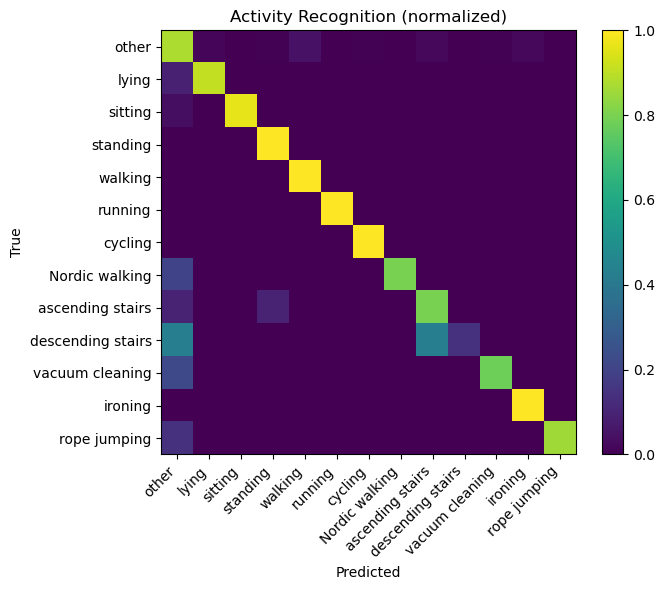


[CLS] Classification report:
                   precision    recall  f1-score   support

            other      0.901     0.877     0.889       146
            lying      0.909     0.909     0.909        22
          sitting      1.000     0.964     0.982        28
         standing      0.857     1.000     0.923        12
          walking      0.741     1.000     0.851        20
          running      1.000     1.000     1.000        11
          cycling      0.923     1.000     0.960        12
   Nordic walking      1.000     0.800     0.889        10
 ascending stairs      0.571     0.800     0.667        10
descending stairs      1.000     0.143     0.250         7
  vacuum cleaning      0.933     0.778     0.848        18
          ironing      0.800     1.000     0.889        12
     rope jumping      1.000     0.857     0.923         7

         accuracy                          0.886       315
        macro avg      0.895     0.856     0.845       315
     weighted avg      0

In [21]:
# === Evaluation, visualization, and saving ===
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Helpers ----------
@torch.no_grad()
def collect_logits_and_labels(model, loader, device):
    model.eval()
    all_logits, all_y = [], []
    for x, y in loader:
        x = x.to(device)
        logits = model(x)
        all_logits.append(logits.cpu())
        all_y.append(y.cpu())
    return torch.cat(all_logits, 0), torch.cat(all_y, 0)


def plot_confusion_matrix(cm, class_names, normalize=True, title="Confusion Matrix"):
    if normalize:
        cm = cm.astype(np.float32) / (cm.sum(axis=1, keepdims=True) + 1e-9)
    plt.figure(figsize=(7,6))
    plt.imshow(cm, aspect='auto')
    plt.title(title + (" (normalized)" if normalize else ""))
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(ticks=np.arange(len(class_names)), labels=class_names, rotation=45, ha='right')
    plt.yticks(ticks=np.arange(len(class_names)), labels=class_names)
    plt.colorbar()
    plt.tight_layout()
    plt.show()

# ---------- A) Classification: metrics & plots ----------
# Collect logits/labels on test set
logits_test, y_test = collect_logits_and_labels(model_cls, test_loader_cls, device)
y_pred = logits_test.argmax(1)

# Basic metrics
acc  = accuracy_score(y_test.numpy(), y_pred.numpy())
f1m  = f1_score(y_test.numpy(), y_pred.numpy(), average="macro")
f1w  = f1_score(y_test.numpy(), y_pred.numpy(), average="weighted")
print(f"[CLS] Test Accuracy: {acc:.3f} | Macro-F1: {f1m:.3f} | Weighted-F1: {f1w:.3f}")

# Confusion matrix
cm = confusion_matrix(y_test.numpy(), y_pred.numpy())
# Recover class names in index order 0..C-1 from the dataset's inv map
# (Assumes you still have `test_cls.inv_class_map` and an ACTIVITY_LABELS map; fallback to raw IDs if not)
try:
    inv_map = test_cls.inv_class_map  # {0: raw_id, 1: raw_id, ...}
    class_names = [ACTIVITY_LABELS.get(inv_map[i], str(inv_map[i])) for i in range(len(inv_map))]
except:
    class_names = [f"class_{i}" for i in range(cm.shape[0])]

plot_confusion_matrix(cm, class_names, normalize=True, title="Activity Recognition")

# Detailed report
print("\n[CLS] Classification report:")
print(classification_report(y_test.numpy(), y_pred.numpy(), target_names=class_names, digits=3))


# ---------- Save model ----------
os.makedirs("checkpoints", exist_ok=True)
torch.save({"state_dict": model_cls.state_dict(),
            "input_dim": xb_cls.shape[-1],
            "num_classes": len(class_names)},
           "checkpoints/har_classification.pt")

print("\nModels saved to ./checkpoints/")

### Step 10: Sensor Group Importance

To study how much each sensor group contributes, we evaluate the trained model while **masking out different groups of signals** (setting them to zero at inference).  

- Groups considered: **HAND IMU, CHEST IMU, ANKLE IMU, HEART RATE**  
- We measure **accuracy** with different combinations.  
- Each group is given equal cost (1), so the x-axis reflects the number of active groups.  

This provides insight into how performance depends on sensor availability, and whether some sensors can be dropped with minimal accuracy loss.

**Why it’s useful**
- Reveals **which sensors matter most** for classification.
- Shows whether acceptable accuracy is achievable with **fewer sensors**, informing energy/battery trade-offs.

**Output**
- A scatter/annotated plot of **Accuracy vs Sensor Cost**, with labels like `HAND+ANKLE`, `CHEST+HR`, and `ALL` for the full set.



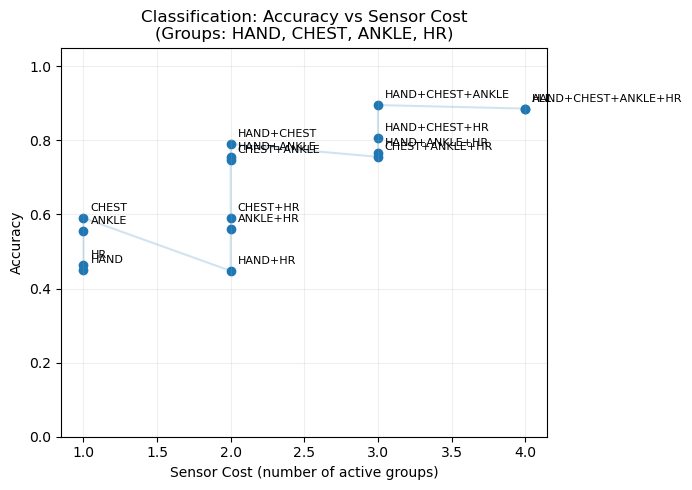

In [22]:
# === Sensor-groups: evaluate subsets without retraining ===
# Groups (equal weights): HAND IMU, CHEST IMU, ANKLE IMU, HEART RATE
# We will mask (zero) the features of groups that are "off" during inference.

import itertools
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---- Derive feature index ranges for groups from batch shapes ----
# Classification: features = [IMU signals ...] + [heart_rate]  -> F_cls = IMU_F + 1
xb_cls, _ = next(iter(test_loader_cls))

F_cls = xb_cls.shape[-1]         
IMU_F_cls = F_cls - 1            # all IMU features in classification

# Split IMU features into 3 blocks ~[17,17,rest] robustly
def imu_blocks(total_imu_feats):
    hand = min(17, total_imu_feats)
    chest = min(17, total_imu_feats - hand)
    ankle = max(0, total_imu_feats - hand - chest)
    # indices for (hand, chest, ankle) over the IMU portion
    hand_idx  = np.arange(0, hand)
    chest_idx = np.arange(hand, hand + chest)
    ankle_idx = np.arange(hand + chest, hand + chest + ankle)
    return hand_idx, chest_idx, ankle_idx

hand_i_cls, chest_i_cls, ankle_i_cls = imu_blocks(IMU_F_cls)

# Build absolute index arrays for each group in each task
# Classification: IMU indices as above, heart_rate is last feature
grp_idx_cls = {
    "HAND":  hand_i_cls,
    "CHEST": chest_i_cls,
    "ANKLE": ankle_i_cls,
    "HR":    np.array([IMU_F_cls])  # heart_rate at last index
}


GROUPS_ALL = ["HAND", "CHEST", "ANKLE", "HR"]  # for subset enumeration in classification

# ---- Masking helpers ----
def mask_features_batch(x, keep_groups, grp_idx_map):
    """
    x: (B, T, F) tensor
    keep_groups: list of group names to keep
    grp_idx_map: dict group -> np.array of feature indices (0..F-1)
    """
    x = x.clone()
    F = x.shape[-1]
    keep = np.zeros(F, dtype=bool)
    for g in keep_groups:
        if g in grp_idx_map:
            keep[grp_idx_map[g]] = True
    # zero out features not kept
    x[..., ~torch.tensor(keep, device=x.device)] = 0.0
    return x

# ---- Evaluation loops over subsets ----
@torch.no_grad()
def eval_cls_with_groups(groups_to_keep):
    model_cls.eval()
    correct, total = 0, 0
    for x, y in test_loader_cls:
        x, y = x.to(device), y.to(device)
        x = mask_features_batch(x, groups_to_keep, grp_idx_cls)
        logits = model_cls(x)
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.numel()
    acc = correct / max(1, total)
    return acc


# ---- Enumerate non-empty subsets and collect metrics ----
results_cls = []  # (cost, acc, label)

# Equal weights: each group costs 1
for k in range(1, len(GROUPS_ALL) + 1):
    for subset in itertools.combinations(GROUPS_ALL, k):
        acc = eval_cls_with_groups(subset)
        label = "+".join(subset)
        cost = len(subset)
        results_cls.append((cost, acc, label))


# Also evaluate "ALL" explicitly for clarity
acc_all = eval_cls_with_groups(GROUPS_ALL)
results_cls.append((len(GROUPS_ALL), acc_all, "ALL"))

# ---- Plot: Classification (Cost vs Accuracy) ----
costs_c, accs_c, labels_c = zip(*results_cls)
plt.figure(figsize=(7,5))
plt.scatter(costs_c, accs_c)
for c, a, lab in results_cls:
    plt.annotate(lab, (c, a), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.plot(sorted(costs_c), [acc for _, acc, _ in sorted(results_cls)], alpha=0.2)  # faint connector
plt.xlabel("Sensor Cost (number of active groups)")
plt.ylabel("Accuracy")
plt.title("Classification: Accuracy vs Sensor Cost\n(Groups: HAND, CHEST, ANKLE, HR)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Step 11: Feature Importance (Cumulative Top-K IMU Signals)

Instead of grouping sensors, here we rank individual IMU features by how much performance drops when each one is masked out.  
This gives a measure of **feature importance** for classification accuracy.

Steps:
1. On the validation set, measure the accuracy drop when each IMU feature is removed (HR excluded here).  
2. Rank the 51 IMU features by importance (largest drop = most important).  
3. On the test set, evaluate models using only the **top-K features** (others zeroed out), for multiple K values.  
4. Plot classification accuracy and regression MAE as a function of the number of retained features.

This experiment shows how quickly performance saturates as we add the most informative features, and whether a small subset of IMU signals can approximate full-sensor performance.


Ranking 51 IMU features on validation set...
Top-10 IMU features (by val acc drop): [45, 43, 19, 22, 13, 21, 18, 20, 23, 49]
K= 1 | [CLS] acc=0.467 
K= 2 | [CLS] acc=0.463 
K= 4 | [CLS] acc=0.508 
K= 8 | [CLS] acc=0.505 
K=12 | [CLS] acc=0.479 
K=16 | [CLS] acc=0.508 
K=24 | [CLS] acc=0.619 
K=28 | [CLS] acc=0.673 
K=32 | [CLS] acc=0.714 
K=36 | [CLS] acc=0.743 
K=40 | [CLS] acc=0.829 
K=44 | [CLS] acc=0.867 
K=48 | [CLS] acc=0.883 
K=51 | [CLS] acc=0.895 
[ALL IMU] [CLS] acc=0.895 


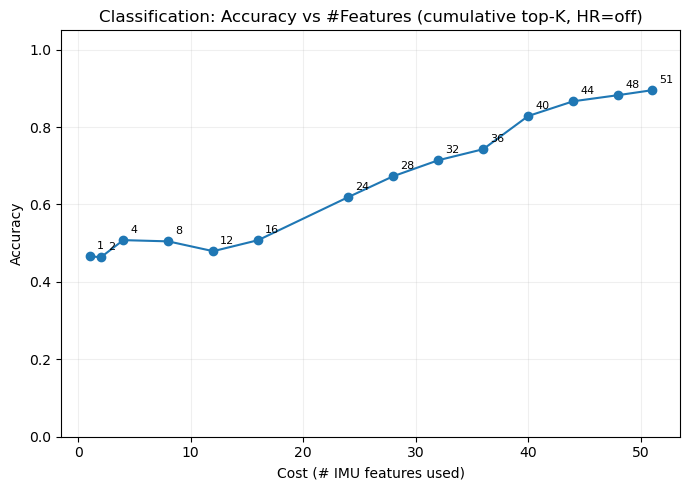

In [23]:
# === evaluate cumulative top-K IMU features (no retraining) ===
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Infer feature dims
xb_cls, _ = next(iter(test_loader_cls))
F_cls = xb_cls.shape[-1]      # expect 52 (51 IMU + 1 HR)
IMU_F_cls = F_cls - 1         # 0..50 are IMU; last is HR

# --- Helpers to keep a given set of IMU feature indices (HR zeroed for cls) ---
def keep_features_cls(x, idx_keep):
    x = x.clone()
    keep_mask_im = np.zeros(IMU_F_cls, dtype=bool)
    keep_mask_im[idx_keep] = True
    keep_full = np.concatenate([keep_mask_im, [False]])  # HR off
    x[..., ~torch.tensor(keep_full, device=x.device)] = 0.0
    return x


# --- Rank IMU features by masking-importance on validation set (classification-driven) ---
@torch.no_grad()
def cls_acc_with_mask(masker=None, loader=None):
    model_cls.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if masker is not None:
            x = masker(x)
        logits = model_cls(x)
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.numel()
    return correct / max(1, total)

# Baseline: all IMU ON, HR OFF
def mask_all_im_on_hr_off(x):
    keep_full = np.concatenate([np.ones(IMU_F_cls, dtype=bool), [False]])
    x = x.clone()
    x[..., ~torch.tensor(keep_full, device=x.device)] = 0.0
    return x

print("Ranking 51 IMU features on validation set...")
acc_base = cls_acc_with_mask(mask_all_im_on_hr_off, val_loader_cls)
drops = []
for f in range(51):
    def drop_f(x, f=f):
        keep = np.ones(IMU_F_cls, dtype=bool)
        keep[f] = False
        keep_full = np.concatenate([keep, [False]])
        x2 = x.clone()
        x2[..., ~torch.tensor(keep_full, device=x.device)] = 0.0
        return x2
    acc_f = cls_acc_with_mask(drop_f, val_loader_cls)
    drops.append(acc_base - acc_f)

ranked_features = np.argsort(drops)[::-1]  # most important first
print("Top-10 IMU features (by val acc drop):", ranked_features[:10].tolist())

# --- Evaluate cumulative top-K on TEST for classification ---
K_LIST = [1, 2, 4, 8, 12, 16, 24, 28, 32, 36, 40, 44, 48, 51]

@torch.no_grad()
def eval_cls_topk(k):
    idx_keep = ranked_features[:k]
    model_cls.eval()
    correct, total = 0, 0
    for x, y in test_loader_cls:
        x, y = x.to(device), y.to(device)
        x = keep_features_cls(x, idx_keep)
        logits = model_cls(x)
        pred = logits.argmax(dim=1)
        correct += (pred == y).sum().item()
        total += y.numel()
    return correct / max(1, total)


results_cls = []
for k in K_LIST:
    acc = eval_cls_topk(k)
    results_cls.append((k, acc))
    print(f"K={k:>2} | [CLS] acc={acc:.3f} ")

# Also compute ALL-IMU baselines (k=51 already covers it but print clearly)
acc_all = eval_cls_topk(51)
print(f"[ALL IMU] [CLS] acc={acc_all:.3f} ")

# --- Plots ---
# Classification: cost (#features) vs Accuracy
ks_c, accs_c = zip(*results_cls)
plt.figure(figsize=(7,5))
plt.plot(ks_c, accs_c, marker='o')
for k, a in results_cls:
    plt.annotate(str(k), (k, a), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.xlabel("Cost (# IMU features used)")
plt.ylabel("Accuracy")
plt.title("Classification: Accuracy vs #Features (cumulative top-K, HR=off)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Task 2: Heart Rate Prediction (Regression)
- **Input:** IMU signals only  
- **Label:** Heart rate (continuous)  
- **Task type:** Regression  
- **Example:** Estimate a subject’s heart rate from their motion signals, linking physical activity intensity to physiological response.


### Step 5: DataLoaders (with Train-Time Augmentation)

Here we build the **regression** pipeline using the **same stratified window indices** as classification.

**Key choices**
- **Same windows, different target:** Inputs are the 51 IMU features; the target is the **mean heart rate** per window.
- **Train-time augmentation (gentle):** Smaller jitter/shift/mask/drop rates than classification to avoid distorting the HR signal-target relationship.
- **Fit normalization on train only:** `train_reg_full` is instantiated with `stats=None` to compute z-score stats on **training windows**; `stats_reg` are then **reused** for val/test to prevent leakage.
- **Index-aligned subsets:** `Subset(..., train_idx/val_idx/test_idx)` applies the previously computed **window-level splits**.

A quick **shape check** confirms the expected `(batch, time, features)` for inputs and `(batch,)` for scalar HR targets.

In [24]:
# Regression DataLoaders (use SAME windowing & indices; gentle aug on train if defined)
augment_reg = AugmentTS(
    p_jitter=0.5,  jitter_std=0.01,
    p_time_shift=0.3, max_shift_frac=0.03,
    p_time_mask=0.2,  max_mask_frac=0.05,
    p_channel_drop=0.1, max_drop_frac=0.03
)

train_reg_full = PAMAP2WindowDataset(all_df, task="regression", window_size=WINDOW, step_size=STEP,
                                     stats=None, transform=augment_reg)
stats_reg = train_reg_full.stats

val_reg_full   = PAMAP2WindowDataset(all_df, task="regression", window_size=WINDOW, step_size=STEP,
                                     stats=stats_reg, transform=None)
test_reg_full  = PAMAP2WindowDataset(all_df, task="regression", window_size=WINDOW, step_size=STEP,
                                     stats=stats_reg, transform=None)

ds_train_reg = Subset(train_reg_full, train_idx)
ds_val_reg   = Subset(val_reg_full,   val_idx)
ds_test_reg  = Subset(test_reg_full,  test_idx)

print(f"[Regression] windows — train: {len(ds_train_reg)}, val: {len(ds_val_reg)}, test: {len(ds_test_reg)}")

train_loader_reg = DataLoader(ds_train_reg, batch_size=BATCH, shuffle=True,  num_workers=0, pin_memory=False)
val_loader_reg   = DataLoader(ds_val_reg,   batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=False)
test_loader_reg  = DataLoader(ds_test_reg,  batch_size=BATCH, shuffle=False, num_workers=0, pin_memory=False)


# Sanity check: feature dims
x_reg, y_reg = next(iter(train_loader_reg))
print("Batch shapes — regression    :", tuple(x_reg.shape), tuple(y_reg.shape))  # (B, T, 52), (B,)

[Regression] windows — train: 1100, val: 158, test: 315
Batch shapes — regression    : (64, 100, 51) (64,)


### Step 6 — Model

Here we define a compact  model that predicts **heart rate (bpm)** from **IMU-only** windows.

**Model: `CNNBiLSTMRegressor`**
- **Inputs:** a window of IMU features with shape `(B, T, F)` (batch, time, features).  
- **Why IMU-only?** We want to *infer* heart rate from motion (no HR sensor at inference).
- **Architecture:**
  1. **Conv1D front-end** (`ConvBlock1D`): learns short-term temporal patterns and denoises signals.  
     - Input is transposed to `(B, F, T)` for convolutions, then back to `(B, T, W)`.
  2. **BiLSTM encoder:** captures longer temporal dependencies in both directions, outputting `(B, T, 2H)`.  
     - We take the **last timestep** as a fixed-length summary `(B, 2H)`.
  3. **Head:** `Dropout + Linear → 1` regresses a single scalar per window and squeezes to `(B,)`.

**Shape flow:** `(B, T, F) → (B, F, T) → (B, W, T) → (B, T, W) → (B, T, 2H) → (B, 2H) → (B,)`.

**Metrics: `regression_metrics`**
We report two complementary error measures:
- **MAE (Mean Absolute Error):** average absolute difference \(|\hat{y} - y|\) — easy to interpret in bpm.
- **RMSE (Root Mean Squared Error):** \(\sqrt{\mathbb{E}[(\hat{y}-y)^2]}\) — penalizes larger errors more strongly.

These are computed with `@torch.no_grad()` to avoid gradient tracking during evaluation.


In [25]:
# === Simple model (regression) ===

class CNNBiLSTMRegressor(nn.Module):
    """Input (B, T, F) -> y_hat (B,) | uses ALL IMU only (F = 52)."""
    def __init__(self, n_features: int, cnn_width=64, lstm_hidden=128, p=0.1):
        super().__init__()
        self.cnn = ConvBlock1D(n_features, cnn_width, p=p)
        self.lstm = nn.LSTM(input_size=cnn_width, hidden_size=lstm_hidden,
                            num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Dropout(p),
            nn.Linear(2*lstm_hidden, 1)
        )

    def forward(self, x):  # x: (B, T, F)
        x = x.transpose(1, 2)           # (B, F, T)
        x = self.cnn(x)                  # (B, W, T)
        x = x.transpose(1, 2)           # (B, T, W)
        out, _ = self.lstm(x)           # (B, T, 2H)
        out = out[:, -1, :]
        return self.head(out).squeeze(-1)  # (B,)


# ----- Utilities -----

@torch.no_grad()
def regression_metrics(y_hat: torch.Tensor, y: torch.Tensor) -> Tuple[float, float]:
    # returns (MAE, RMSE)
    mae = (y_hat - y).abs().mean().item()
    rmse = torch.sqrt(((y_hat - y) ** 2).mean()).item()
    return mae, rmse

### Step 7: Training and Evaluation Loops

These functions define **one epoch** of training and evaluation for the heart-rate regressor.

**`train_one_epoch_reg`**
- **Mode:** `model.train()` enables gradient computation and dropout.
- **Per-batch steps:**
  1. Move inputs/targets to device and cast targets to `float`.
  2. Zero gradients, forward pass to get predictions `y_hat`.
  3. Compute regression loss (`criterion`, e.g., MSE).
  4. Backpropagate and update weights (`optimizer.step()`).
  5. Track running **loss**, **MAE**, and **RMSE** for monitoring.
- **Returns:** average loss, MAE, RMSE over all batches in the epoch.

**`eval_epoch_reg`**
- **Mode:** `model.eval()` with `@torch.no_grad()` disables gradient tracking for speed and stability.
- **Per-batch steps:** forward pass, compute loss and metrics (MAE, RMSE), accumulate averages.
- **Returns:** validation/test **mean loss**, **MAE**, **RMSE** for the epoch.

**Why both MAE and RMSE?**  
- **MAE** is easy to interpret in bpm and robust to outliers.  
- **RMSE** penalizes large errors more strongly, highlighting rare but significant mistakes.

Together, these loops provide clear, comparable signals about model fit (train) and **generalization** (val/test).

In [26]:
# ----- Train/Eval loops -----

def train_one_epoch_reg(model, loader, optimizer, criterion):
    model.train()
    running_loss, running_mae, running_rmse, n_batches = 0.0, 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device).float()
        optimizer.zero_grad()
        y_hat = model(x)
        loss = criterion(y_hat, y)
        loss.backward()
        optimizer.step()
        mae, rmse = regression_metrics(y_hat, y)
        running_loss += loss.item()
        running_mae  += mae
        running_rmse += rmse
        n_batches += 1
    return running_loss / n_batches, running_mae / n_batches, running_rmse / n_batches

@torch.no_grad()
def eval_epoch_reg(model, loader, criterion):
    model.eval()
    running_loss, running_mae, running_rmse, n_batches = 0.0, 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device).float()
        y_hat = model(x)
        loss = criterion(y_hat, y)
        mae, rmse = regression_metrics(y_hat, y)
        running_loss += loss.item()
        running_mae  += mae
        running_rmse += rmse
        n_batches += 1
    return running_loss / n_batches, running_mae / n_batches, running_rmse / n_batches

### Step 8: Model Instantiation and Training

Here we define, train, and evaluate the **CNN + BiLSTM regressor** for heart-rate prediction.

**1) Infer input dimensions**
We peek one batch to get the **feature dimension** (`input_dim_reg`) used to configure the model. This ensures the network matches the window shape coming from the dataloader.

**2) Model + initialization**
We instantiate `CNNBiLSTMRegressor` (Conv1D front-end → BiLSTM → Linear head) and apply the same **weight initialization** strategy used for classification to stabilize training.

**3) Optimization setup**
- **Optimizer:** Adam (`lr=1e-3`) with **weight decay** (`1e-4`) for regularization.  
- **Loss:** MSE, standard for regression.  
- **Scheduler:** Cosine annealing gradually decreases the learning rate over `EPOCHS`, ending at `eta_min=1e-5`.

**4) Early stopping**
- We track **validation loss** each epoch and keep the **best model state** seen so far.  
- A small **improvement threshold** (`IMPROVE_DELTA`) avoids resetting patience for tiny numerical fluctuations.  
- If no improvement for `PATIENCE=5` epochs, training stops and we **restore the best weights**.

**5) Final evaluation**
After training, we evaluate on the **test set**, reporting:
- **Loss (MSE)**
- **MAE** (average absolute bpm error)
- **RMSE** (root mean squared bpm error)

This mirrors the classification setup, providing a consistent, regularized training routine with LR scheduling and robust stopping criteria.

In [27]:
# ----- Instantiate models from loaders' feature dims -----
# Peek a batch to infer input dims 
xb_reg, yb_reg = next(iter(train_loader_reg))

input_dim_reg = xb_reg.shape[-1]

print(f"Input dims — regression: {input_dim_reg}")



model_reg = CNNBiLSTMRegressor(n_features=input_dim_reg, cnn_width=64, lstm_hidden=256, p=0.2).to(device)

init_weights(model_reg)


opt_reg = torch.optim.Adam(model_reg.parameters(), lr=1e-3, weight_decay=1e-4)

crit_reg = nn.MSELoss()


EPOCHS = 100         # can be large; early stopping will cut it short
PATIENCE = 5
IMPROVE_DELTA = 1e-7  # minimum improvement to reset patience

scheduler_reg = CosineAnnealingLR(opt_reg, T_max=EPOCHS, eta_min=1e-5)


# ---------- Regression with early stopping ----------
best_val_loss = float("inf")
pat = 0
best_state_reg = None

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_mae, tr_rmse = train_one_epoch_reg(model_reg, train_loader_reg, opt_reg, crit_reg)
    va_loss, va_mae, va_rmse = eval_epoch_reg(model_reg, val_loader_reg, crit_reg)
    print(f"[REG] Epoch {epoch:02d} | train loss {tr_loss:.4f} MAE {tr_mae:.2f} RMSE {tr_rmse:.2f} | "
          f"val loss {va_loss:.4f} MAE {va_mae:.2f} RMSE {va_rmse:.2f}")
    scheduler_reg.step()

    if va_loss < best_val_loss - IMPROVE_DELTA:
        best_val_loss = va_loss
        best_state_reg = copy.deepcopy(model_reg.state_dict())
        pat = 0
    else:
        pat += 1
        if pat >= PATIENCE:
            print(f"[REG] Early stopping at epoch {epoch} (no val loss improvement for {PATIENCE} epochs).")
            break

# restore best weights before test
if best_state_reg is not None:
    model_reg.load_state_dict(best_state_reg)

te_loss, te_mae, te_rmse = eval_epoch_reg(model_reg, test_loader_reg, crit_reg)
print(f"[REG] Test  | loss {te_loss:.4f} MAE {te_mae:.2f} RMSE {te_rmse:.2f}")

Input dims — regression: 51
[REG] Epoch 01 | train loss 873.5281 MAE 28.80 RMSE 28.91 | val loss 439.8339 MAE 20.85 RMSE 20.97
[REG] Epoch 02 | train loss 138.7625 MAE 10.79 RMSE 11.12 | val loss 32.5043 MAE 5.24 RMSE 5.67
[REG] Epoch 03 | train loss 11.4882 MAE 2.71 RMSE 3.26 | val loss 4.8927 MAE 1.77 RMSE 2.20
[REG] Epoch 04 | train loss 7.2181 MAE 2.17 RMSE 2.68 | val loss 5.2498 MAE 1.83 RMSE 2.29
[REG] Epoch 05 | train loss 6.3822 MAE 2.05 RMSE 2.52 | val loss 4.7998 MAE 1.76 RMSE 2.17
[REG] Epoch 06 | train loss 6.4442 MAE 2.04 RMSE 2.53 | val loss 4.8045 MAE 1.75 RMSE 2.17
[REG] Epoch 07 | train loss 6.2989 MAE 2.03 RMSE 2.49 | val loss 4.7674 MAE 1.75 RMSE 2.16
[REG] Epoch 08 | train loss 6.7343 MAE 2.12 RMSE 2.59 | val loss 4.7108 MAE 1.74 RMSE 2.15
[REG] Epoch 09 | train loss 6.3871 MAE 2.02 RMSE 2.51 | val loss 4.4413 MAE 1.69 RMSE 2.08
[REG] Epoch 10 | train loss 6.0153 MAE 1.98 RMSE 2.44 | val loss 4.0294 MAE 1.62 RMSE 1.99
[REG] Epoch 11 | train loss 5.7273 MAE 1.95 RMSE

### Step 9: Evaluation, Visualization, and Saving

We evaluate the trained regression model on the **test set** and visualize key results.

- Metrics: MAE, RMSE, R²
- Plots: Predicted vs. True scatter (with y=x reference) and a residual histogram

Finally, we **save checkpoint** (state dict + input dims) for the model to `./checkpoints/` for reuse.


[REG] Test MAE: 1.01 bpm | RMSE: 1.28 bpm | R^2: 0.690


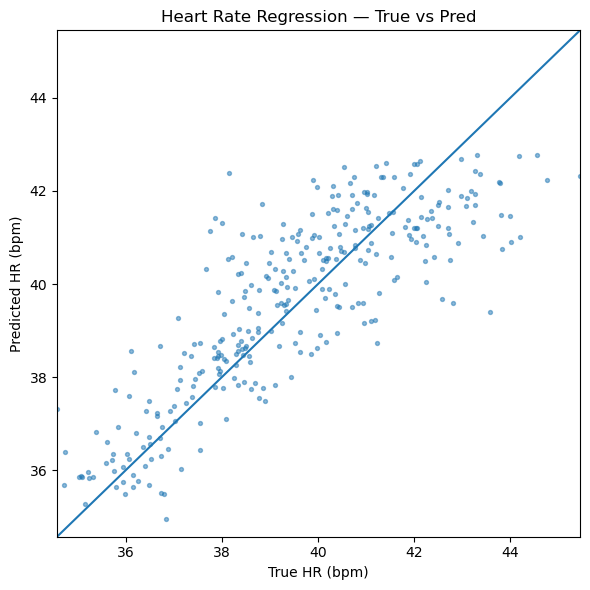

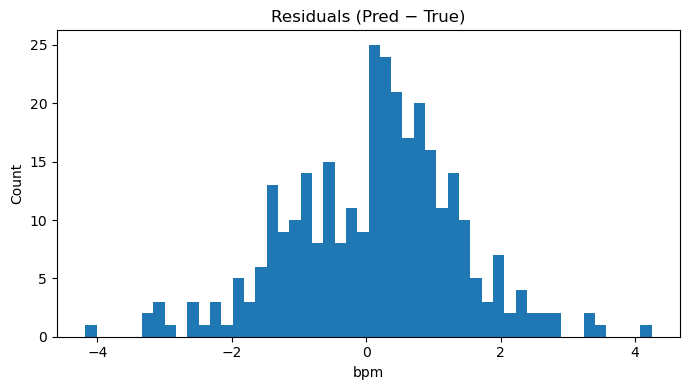


Model saved to ./checkpoints/


In [28]:
# Evaluation, visualization, and saving 

# ---------- Helpers ----------

@torch.no_grad()
def collect_preds_and_targets_reg(model, loader, device):
    model.eval()
    y_hat_list, y_list = [], []
    for x, y in loader:
        x = x.to(device)
        y_hat = model(x).cpu().numpy()
        y_list.append(y.numpy())
        y_hat_list.append(y_hat)
    return np.concatenate(y_hat_list), np.concatenate(y_list)


# ---------- B) Regression: metrics & plots ----------
y_hat_test, y_true_test = collect_preds_and_targets_reg(model_reg, test_loader_reg, device)

mae  = np.mean(np.abs(y_hat_test - y_true_test))
rmse = np.sqrt(np.mean((y_hat_test - y_true_test)**2))
r2   = r2_score(y_true_test, y_hat_test)
print(f"\n[REG] Test MAE: {mae:.2f} bpm | RMSE: {rmse:.2f} bpm | R^2: {r2:.3f}")

# Scatter: Pred vs True
plt.figure(figsize=(6,6))
plt.scatter(y_true_test, y_hat_test, s=8, alpha=0.5)
lims = [min(y_true_test.min(), y_hat_test.min()), max(y_true_test.max(), y_hat_test.max())]
plt.plot(lims, lims)  # y=x
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("True HR (bpm)")
plt.ylabel("Predicted HR (bpm)")
plt.title("Heart Rate Regression — True vs Pred")
plt.tight_layout()
plt.show()

# Residual histogram
resid = y_hat_test - y_true_test
plt.figure(figsize=(7,4))
plt.hist(resid, bins=50)
plt.title("Residuals (Pred − True)")
plt.xlabel("bpm")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# ---------- Save model ----------
os.makedirs("checkpoints", exist_ok=True)

torch.save({"state_dict": model_reg.state_dict(),
            "input_dim": xb_reg.shape[-1]},
           "checkpoints/hr_regression.pt")

print("\nModel saved to ./checkpoints/")

### Step 10: Sensor Group Importance

To study how much each sensor group contributes, we evaluate the trained models while **masking out different groups of signals** (setting them to zero at inference).  

- Groups considered: **HAND IMU, CHEST IMU, ANKLE IMU, HEART RATE**  
- We measure **MAE** when predicting heart rate.  
- Each group is given equal cost (1), so the x-axis reflects the number of active groups.  

**Why it’s useful**
- Shows how well heart rate can be estimated when **only some sensors are active**, informing energy/battery trade-offs for continuous monitoring.  
- Highlights which **IMU locations** contribute most to HR estimation.

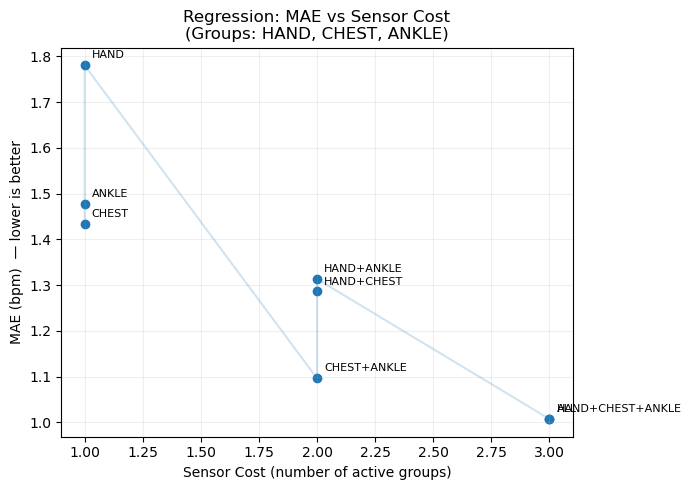

In [29]:
# Regression:     features = [IMU signals ...]                 -> F_reg = IMU_F
xb_reg, _ = next(iter(test_loader_reg))

F_reg = xb_reg.shape[-1]         

IMU_F_reg = F_reg                # all IMU features in regression

hand_i_reg, chest_i_reg, ankle_i_reg = imu_blocks(IMU_F_reg)


# Regression: only IMU features (no HR)
grp_idx_reg = {
    "HAND":  hand_i_reg,
    "CHEST": chest_i_reg,
    "ANKLE": ankle_i_reg,
    # "HR" not present as input for regression
}

GROUPS_NO_HR = ["HAND", "CHEST", "ANKLE"]      # for regression



# ---- Evaluation loops over subsets ----
@torch.no_grad()
def eval_reg_with_groups(groups_to_keep):
    model_reg.eval()
    se_sum, ae_sum, n = 0.0, 0.0, 0
    for x, y in test_loader_reg:
        x, y = x.to(device), y.to(device).float()
        x = mask_features_batch(x, groups_to_keep, grp_idx_reg)
        y_hat = model_reg(x)
        diff = (y_hat - y)
        se_sum += (diff * diff).sum().item()
        ae_sum += diff.abs().sum().item()
        n += y.numel()
    mae  = ae_sum / max(1, n)
    rmse = (se_sum / max(1, n)) ** 0.5
    return mae, rmse



# ---- Enumerate non-empty subsets and collect metrics ----
results_reg = []  # (cost, mae, rmse, label)


for k in range(1, len(GROUPS_NO_HR) + 1):
    for subset in itertools.combinations(GROUPS_NO_HR, k):
        mae, rmse = eval_reg_with_groups(subset)
        label = "+".join(subset)
        cost = len(subset)
        results_reg.append((cost, mae, rmse, label))


mae_all, rmse_all = eval_reg_with_groups(GROUPS_NO_HR)
results_reg.append((len(GROUPS_NO_HR), mae_all, rmse_all, "ALL"))



# ---- Plot: Regression (Cost vs MAE) ----
costs_r, maes_r, rmses_r, labels_r = zip(*results_reg)
plt.figure(figsize=(7,5))
plt.scatter(costs_r, maes_r)
for c, m, _, lab in results_reg:
    plt.annotate(lab, (c, m), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.plot(sorted(costs_r), [m for _, m, _, _ in sorted(results_reg)], alpha=0.2)
plt.xlabel("Sensor Cost (number of active groups)")
plt.ylabel("MAE (bpm)  — lower is better")
plt.title("Regression: MAE vs Sensor Cost\n(Groups: HAND, CHEST, ANKLE)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Step 11: Feature Importance (Cumulative Top-K IMU Signals)

Instead of grouping sensors, here we rank individual IMU features by how much performance drops when each one is masked out.  
This gives a measure of **feature importance** for regression performance.

Steps:
1. On the test set, evaluate models using only the **top-K features** (others zeroed out), for multiple K values. (We use the top-K features from classification)
4. Plot regression MAE as a function of the number of retained features.

This experiment shows how quickly performance saturates as we add the most informative features, and whether a small subset of IMU signals can approximate full-sensor performance.

K= 1 | [REG] MAE=1.92, RMSE=2.33
K= 2 | [REG] MAE=1.83, RMSE=2.23
K= 4 | [REG] MAE=1.68, RMSE=2.03
K= 8 | [REG] MAE=1.60, RMSE=1.93
K=12 | [REG] MAE=1.45, RMSE=1.76
K=16 | [REG] MAE=1.36, RMSE=1.68
K=24 | [REG] MAE=1.34, RMSE=1.68
K=28 | [REG] MAE=1.19, RMSE=1.51
K=32 | [REG] MAE=1.16, RMSE=1.48
K=36 | [REG] MAE=1.12, RMSE=1.42
K=40 | [REG] MAE=1.08, RMSE=1.38
K=44 | [REG] MAE=1.07, RMSE=1.36
K=48 | [REG] MAE=1.04, RMSE=1.32
K=51 | [REG] MAE=1.01, RMSE=1.28
[ALL IMU] | [REG] MAE=1.01, RMSE=1.28


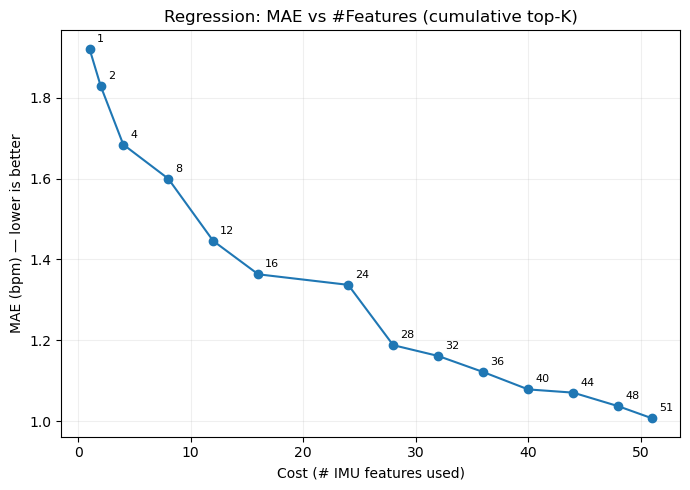

In [30]:
# Infer feature dims
xb_reg, _ = next(iter(test_loader_reg))
F_reg = xb_reg.shape[-1]      # expect 51 (IMU only)
IMU_F_reg = F_reg             # 0..50 are IMU


# --- Helpers to keep a given set of IMU feature indices ---

def keep_features_reg(x, idx_keep):
    x = x.clone()
    keep_mask_im = np.zeros(IMU_F_reg, dtype=bool)
    keep_mask_im[idx_keep] = True
    x[..., ~torch.tensor(keep_mask_im, device=x.device)] = 0.0
    return x



# --- Evaluate cumulative top-K on TEST for regression ---
K_LIST = [1, 2, 4, 8, 12, 16, 24, 28, 32, 36, 40, 44, 48, 51]


@torch.no_grad()
def eval_reg_topk(k):
    idx_keep = ranked_features[:k]
    model_reg.eval()
    se_sum, ae_sum, n = 0.0, 0.0, 0
    for x, y in test_loader_reg:
        x, y = x.to(device), y.to(device).float()
        x = keep_features_reg(x, idx_keep)
        y_hat = model_reg(x)
        diff = y_hat - y
        se_sum += (diff * diff).sum().item()
        ae_sum += diff.abs().sum().item()
        n += y.numel()
    mae  = ae_sum / max(1, n)
    rmse = (se_sum / max(1, n)) ** 0.5
    return mae, rmse


results_reg = []


for k in K_LIST:
    mae, rmse = eval_reg_topk(k)
    results_reg.append((k, mae, rmse))
    print(f"K={k:>2} | [REG] MAE={mae:.2f}, RMSE={rmse:.2f}")


mae_all, rmse_all = eval_reg_topk(51)
print(f"[ALL IMU] | [REG] MAE={mae_all:.2f}, RMSE={rmse_all:.2f}")


# Regression: cost (#features) vs MAE
ks_r, maes_r, rmses_r = zip(*results_reg)
plt.figure(figsize=(7,5))
plt.plot(ks_r, maes_r, marker='o')
for k, m, _ in results_reg:
    plt.annotate(str(k), (k, m), textcoords="offset points", xytext=(5,5), fontsize=8)
plt.xlabel("Cost (# IMU features used)")
plt.ylabel("MAE (bpm) — lower is better")
plt.title("Regression: MAE vs #Features (cumulative top-K)")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Conclusion and Future Directions

In this project, we:  
- Explored the **PAMAP2 wearable sensor dataset** and verified its properties.  
- Built preprocessing and windowing pipelines to prepare data for deep learning.  
- Trained two models:  
  - **Activity recognition (classification)** using IMU + HR signals.  
  - **Heart rate prediction (regression)** using IMU signals only.  
- Evaluated model performance with clear metrics and visualizations.  
- Conducted studies at the sensor-group and feature level to analyze the contribution of different sensors.  

---

### What more could be done:
- **Model improvements:** Try deeper CNNs or Transformer-based sequence models.  
- **Multitask learning:** Jointly train classification and regression in one shared model.  
- **Energy-awareness:** Use sensor-group insights to design **sensor selection policies** that save energy while keeping accuracy high.  
- **Cross-subject generalization:** In our current setup, the dataset is split at the window level, meaning windows from the same subject can appear across training, validation, and test sets. While this allows us to train and evaluate the models, it may overestimate performance due to temporal and subject-specific correlations. For more realistic deployment scenarios, it is preferable to adopt **subject-based splits**, where models are validated on completely unseen subjects, thereby providing a stronger measure of generalization and robustness.
- **Explainability:** Use feature attribution (e.g., SHAP, saliency maps) to understand which signals drive decisions.  

Overall, this project demonstrates a **practical workflow** for working with wearable datasets: from raw signal analysis to modeling, evaluation, and sensor-usage analysis. It also opens the door to many extensions in **model design, efficiency, and interpretability**.